# 02. Explore the data with an expert eye (Task 2)

This notebook answers the three business questions from `01_clean.ipynb`, finds what drives delays and cancellations, checks that the main findings are real and not chance, and ends with the 5 best findings and the choice of the second prediction.

**Which data is used.** Only the **training months, January to September 2023** (330,883 flights). The test months (October to December) are not touched here, so nothing learned in this notebook can leak from the test part into the models. Everything that says "late" uses the definition of the plan: `late` = left more than 15 minutes after schedule, **or** was cancelled. `cancelled` = no departure time.

**Why days are resampled, not flights.** All flights of one day share the same weather and the same airport problems, so they are not independent. A normal chi-square test or a flight-by-flight interval would be far too confident. Every interval in this notebook comes from a **day bootstrap**: whole days are resampled (1,000 times, `random_state=42`), which respects that a bad day is one event, not 1,200 separate ones. Chi-square is still shown (the task asks for it) together with its effect size (Cramer's V).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from utils import *

set_seed()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
fmt_p = lambda p: "p < 1e-300" if p < 1e-300 else f"p = {p:.2g}"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, ORANGE, GREY, RED = "#2b6cb0", "#dd6b20", "#718096", "#c53030"

fl = pd.read_parquet(PROC / "flights_clean.parquet")
we = pd.read_parquet(PROC / "weather_clean.parquet")
pl = pd.read_parquet(PROC / "planes_clean.parquet")
al = pd.read_parquet(PROC / "airlines_clean.parquet")

tr = fl[fl.month.isin(TRAIN_MONTHS)].copy()          # training months only
assert len(tr) == 330_883
tr["date"] = tr.sched_dt.dt.tz_localize(None).dt.normalize()     # scheduled day (New York)
tr["dow"] = tr.sched_dt.dt.dayofweek
tr["departed"] = tr.dep_delay.notna()
tr["late15"] = tr.dep_delay.gt(15).fillna(False)                 # late among flights that left
tr["dband"] = pd.cut(tr.distance.astype(float), [0, 500, 1000, 1500, 2500, 6000],
                     labels=["<500", "500-1000", "1000-1500", "1500-2500", ">2500"]).astype(str)

# Weather of the scheduled hour: the correct join (flights converted to UTC) ...
tr = tr.merge(we.drop(columns=["wind_calm"]), on=["origin", "time_hour_utc"], how="left", validate="m:1")
# ... and the literal join of the course sheet (raw time_hour text), kept only to compare
wl = pd.read_csv(RAW / "weather.csv", usecols=["origin", "time_hour", "precip", "visib", "wind_gust"])
wl["time_hour_naive"] = pd.to_datetime(wl.time_hour)
wl = wl.drop(columns="time_hour").rename(columns={"precip": "precip_lit", "visib": "visib_lit", "wind_gust": "wind_gust_lit"})
tr = tr.merge(wl, on=["origin", "time_hour_naive"], how="left", validate="m:1")
assert len(tr) == 330_883

names = al.set_index("carrier")["name"].str.replace(r" (Inc\.|Co\.|Air Lines|Airways|Airline|Air)\b.*", "", regex=True)
print("training flights:", len(tr), "| days:", tr.date.nunique(), "| late rate: %.4f | cancelled rate: %.4f" % (tr.late.mean(), tr.cancelled.mean()))

training flights: 330883 | days: 273 | late rate: 0.2571 | cancelled rate: 0.0318


## Question 1: which flights leave late or are cancelled? (when, where, who)

### When: hour of the day, day of the week, month

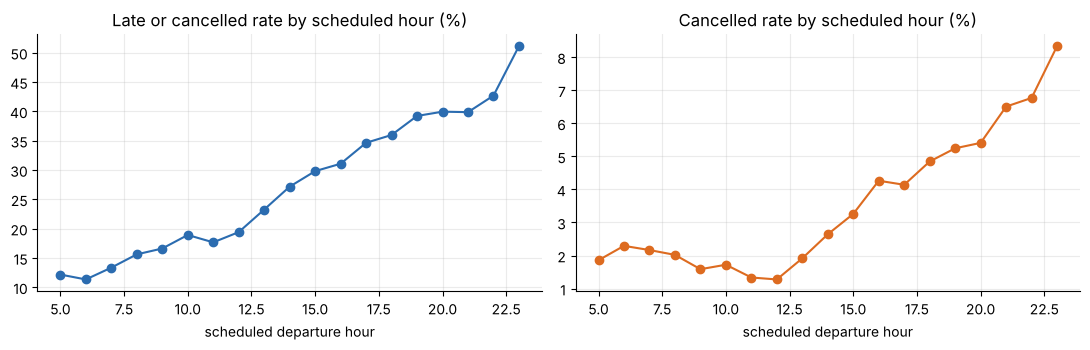

hour,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
flights,2475.0,21846.0,22615.0,21673.0,24124.0,18112.0,19982.0,15969.0,18621.0,20505.0,22149.0,20361.0,21085.0,19733.0,21184.0,18714.0,15910.0,5645.0,180.0
late,12.2,11.3,13.3,15.6,16.6,18.9,17.7,19.4,23.2,27.2,29.8,31.1,34.6,36.0,39.2,39.9,39.9,42.7,51.1
cancelled,1.9,2.3,2.2,2.0,1.6,1.7,1.3,1.3,1.9,2.6,3.3,4.3,4.1,4.8,5.2,5.4,6.5,6.8,8.3


In [2]:
by_hour = tr.groupby("hour").agg(flights=("late", "size"), late=("late", "mean"), cancelled=("cancelled", "mean"))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(by_hour.index, 100 * by_hour.late, marker="o", color=BLUE); ax[0].set_title("Late or cancelled rate by scheduled hour (%)")
ax[1].plot(by_hour.index, 100 * by_hour.cancelled, marker="o", color=ORANGE); ax[1].set_title("Cancelled rate by scheduled hour (%)")
for a in ax: a.set_xlabel("scheduled departure hour")
plt.tight_layout(); plt.show()
display((by_hour.assign(late=100 * by_hour.late, cancelled=100 * by_hour.cancelled)).round(1).T)

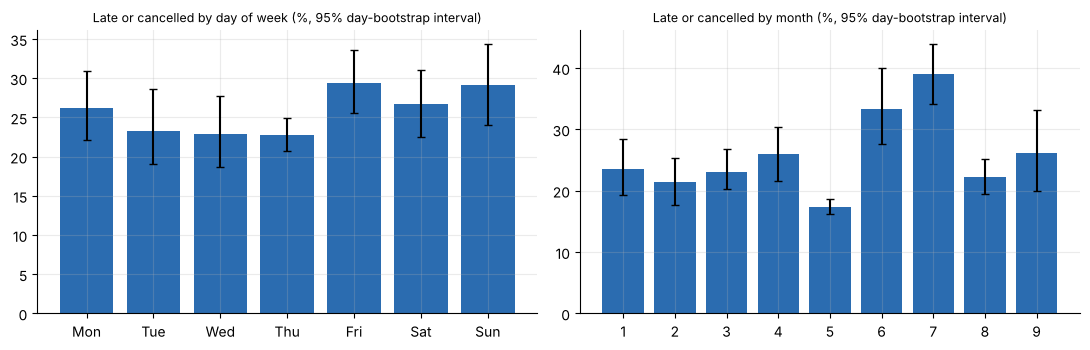

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
late %,26.17,23.32,22.94,22.77,29.37,26.67,29.17
cancelled %,3.49,3.58,2.07,1.51,3.58,3.46,4.73


month,1,2,3,4,5,6,7,8,9
late %,23.50,21.39,23.10,26.06,17.37,33.32,39.07,22.2,26.13
cancelled %,1.36,1.57,1.45,2.75,0.38,6.05,8.68,1.7,5.02


In [3]:
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_dow = day_bootstrap_rate(tr, "dow"); by_dow.index = dow_names
by_month = day_bootstrap_rate(tr, "month")
canc_dow = day_bootstrap_rate(tr, "dow", y="cancelled"); canc_dow.index = dow_names
canc_month = day_bootstrap_rate(tr, "month", y="cancelled")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, t, ttl in [(ax[0], by_dow, "Late or cancelled by day of week (%, 95% day-bootstrap interval)"),
                  (ax[1], by_month, "Late or cancelled by month (%, 95% day-bootstrap interval)")]:
    a.bar(range(len(t)), 100 * t.rate, color=BLUE, yerr=[100 * (t.rate - t.low), 100 * (t.high - t.rate)], capsize=3)
    a.set_xticks(range(len(t))); a.set_xticklabels(t.index); a.set_title(ttl, fontsize=9)
plt.tight_layout(); plt.show()
display(pd.concat({"late %": 100 * by_dow.rate, "cancelled %": 100 * canc_dow.rate}, axis=1).round(2).T)
display(pd.concat({"late %": 100 * by_month.rate, "cancelled %": 100 * canc_month.rate}, axis=1).round(2).T)

### Where: origin airport, distance, destination

In [4]:
by_origin = day_bootstrap_rate(tr, "origin").join(day_bootstrap_rate(tr, "origin", y="cancelled")[["rate"]].rename(columns={"rate": "cancelled_rate"}))
by_dband = day_bootstrap_rate(tr, "dband").loc[["<500", "500-1000", "1000-1500", "1500-2500", ">2500"]]
print("By origin (late = rate of late or cancelled):"); display((by_origin[["flights"]].join(100 * by_origin[["rate", "low", "high", "cancelled_rate"]])).round(1))
print("By distance band (miles):"); display((by_dband[["flights"]].join(100 * by_dband[["rate", "low", "high"]])).round(1))

dest_n = tr.dest.value_counts()
big = tr[tr.dest.isin(dest_n[dest_n >= 1000].index)]
by_dest = day_bootstrap_rate(big, "dest").sort_values("rate")
print(f"Destinations with at least 1,000 training flights: {len(by_dest)}")
print("Most reliable 5:"); display((by_dest.head(5)[["flights"]].join(100 * by_dest.head(5)[["rate", "low", "high"]])).round(1))
print("Least reliable 5:"); display((by_dest.tail(5)[["flights"]].join(100 * by_dest.tail(5)[["rate", "low", "high"]])).round(1))

By origin (late = rate of late or cancelled):


,flights,rate,low,high,cancelled_rate
origin,,,,,
EWR,105519,28.6,26.7,30.5,3.4
JFK,101195,26.6,25.0,28.2,2.8
LGA,124169,22.6,20.8,24.7,3.3


By distance band (miles):


,flights,rate,low,high
dband,,,,
<500,93021,22.7,20.8,24.7
500-1000,107074,25.3,23.7,27.1
1000-1500,68600,27.8,26.3,29.4
1500-2500,52010,28.8,27.4,30.4
>2500,10178,27.5,26.0,29.1


Destinations with at least 1,000 training flights: 64
Most reliable 5:


,flights,rate,low,high
dest,,,,
AVL,1205,16.5,14.2,19.0
SDF,1970,17.4,15.0,19.9
DCA,7395,17.6,15.8,19.6
RIC,2840,18.0,15.4,20.3
CMH,5824,18.2,16.0,20.4


Least reliable 5:


,flights,rate,low,high
dest,,,,
PBI,6186,31.7,29.5,33.8
MCO,13244,34.2,32.4,36.1
FLL,10634,34.5,32.6,36.6
LAS,4471,35.4,33.2,37.6
SJU,4152,38.0,35.9,40.0


### Who: airline

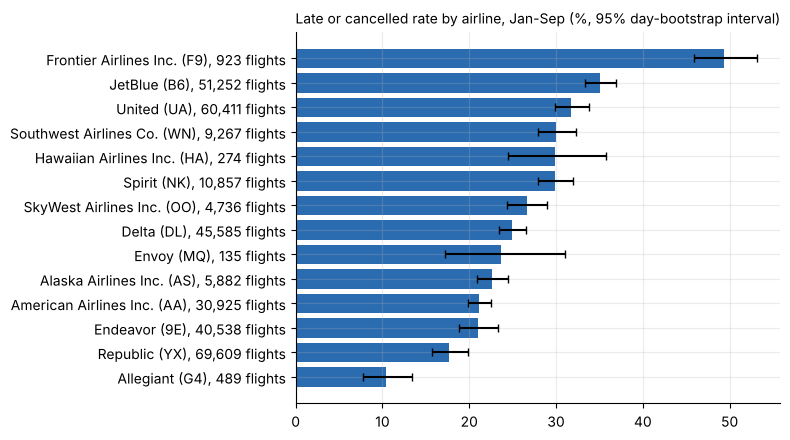

In [5]:
by_car = day_bootstrap_rate(tr, "carrier").sort_values("rate")
by_car_c = day_bootstrap_rate(tr, "carrier", y="cancelled")
fig, ax = plt.subplots(figsize=(8, 4.5))
lab = [f"{names[c]} ({c}), {int(n):,} flights" for c, n in zip(by_car.index, by_car.flights)]
ax.barh(lab, 100 * by_car.rate, color=BLUE, xerr=[100 * (by_car.rate - by_car.low), 100 * (by_car.high - by_car.rate)], capsize=3)
ax.set_title("Late or cancelled rate by airline, Jan-Sep (%, 95% day-bootstrap interval)", fontsize=10)
plt.tight_layout(); plt.show()

**Raw rates mix airlines with very different schedules** (early flights, short flights, one airport). To compare airlines fairly, each airline's observed late rate is divided by the rate that would be **expected** for flights at the same hour, month, origin airport and distance band, taking the average of all airlines in that cell. A ratio above 1 means "later than expected for the flights it flies".

In [6]:
cell = ["hour", "month", "origin", "dband"]
tr["exp_late"] = tr.groupby(cell)["late"].transform("mean")
pd_car = tr.groupby(["date", "carrier"]).agg(obs=("late", "sum"), exp=("exp_late", "sum")).reset_index()
rows = []
for c in sorted(tr.carrier.unique()):
    t = pd_car[pd_car.carrier == c].set_index("date")[["obs", "exp"]]
    est, lo, hi = day_bootstrap(t, lambda s: s.obs / s.exp)
    rows.append({"carrier": c, "airline": names[c], "flights": int((tr.carrier == c).sum()), "raw late %": 100 * tr.loc[tr.carrier == c, "late"].mean(),
                 "observed / expected": est, "low": lo, "high": hi})
carrier_oe = pd.DataFrame(rows).set_index("carrier").sort_values("observed / expected", ascending=False)
display(carrier_oe.round(3))

,airline,flights,raw late %,observed / expected,low,high
carrier,,,,,,
B6,JetBlue,51252,35.078,1.258,1.203,1.313
F9,Frontier Airlines Inc.,923,49.404,1.253,1.167,1.340
WN,Southwest Airlines Co.,9267,29.945,1.207,1.128,1.296
NK,Spirit,10857,29.916,1.096,1.029,1.165
UA,United,60411,31.741,1.074,1.020,1.131
MQ,Envoy,135,23.704,1.057,0.782,1.352
HA,Hawaiian Airlines Inc.,274,29.927,1.047,0.855,1.240
OO,SkyWest Airlines Inc.,4736,26.710,0.997,0.916,1.080
DL,Delta,45585,24.925,0.993,0.940,1.050


## Question 2: how reliable are airlines and airports, and how much does the weather explain?

The airline table above is part of the answer. The weather is joined by the **UTC-aware** method (decision D4); the literal join is shown beside it to make the difference visible.

In [7]:
def gap_table(df, flag, label):
    """Late rate when the flag is true vs false, the gap in percentage points, with a day-bootstrap interval,
    and the same gap after taking out hour, month and origin (observed / expected)."""
    d = df[df[flag].notna()].copy()
    d["exp2"] = d.groupby(["hour", "month", "origin"])["late"].transform("mean")
    d["f"] = d[flag].astype(bool)
    t = d.groupby(["date"]).apply(lambda g: pd.Series({"y1": g.late[g.f].sum(), "n1": g.f.sum(), "y0": g.late[~g.f].sum(), "n0": (~g.f).sum(),
                                                      "o1": g.late[g.f].sum(), "e1": g.exp2[g.f].sum()}), include_groups=False)
    gap = day_bootstrap(t[["y1", "n1", "y0", "n0"]], lambda s: 100 * (s.y1 / s.n1 - s.y0 / s.n0))
    adj = day_bootstrap(t[["o1", "e1"]], lambda s: s.o1 / s.e1)
    return {"condition": label, "share of flights %": 100 * d.f.mean(), "late % if yes": 100 * d.late[d.f].mean(), "late % if no": 100 * d.late[~d.f].mean(),
            "gap (points)": gap[0], "gap low": gap[1], "gap high": gap[2], "obs/exp if yes (same hour, month, origin)": adj[0], "obs/exp low": adj[1], "obs/exp high": adj[2]}

tr["rain"] = tr.precip.gt(0).where(tr.precip.notna())
tr["low_visib"] = tr.visib.lt(3).where(tr.visib.notna())
tr["gust25"] = tr.wind_gust.ge(25).where(tr.wind_gust.notna())
tr["rain_lit"] = tr.precip_lit.gt(0).where(tr.precip_lit.notna())
tr["low_visib_lit"] = tr.visib_lit.lt(3).where(tr.visib_lit.notna())
tr["gust25_lit"] = tr.wind_gust_lit.ge(25).where(tr.wind_gust_lit.notna())

wx = pd.DataFrame([gap_table(tr, "rain", "rain or snow in the hour (UTC-aware join)"),
                   gap_table(tr, "rain_lit", "rain or snow in the hour (literal join)"),
                   gap_table(tr, "low_visib", "visibility under 3 miles (UTC-aware join)"),
                   gap_table(tr, "low_visib_lit", "visibility under 3 miles (literal join)"),
                   gap_table(tr, "gust25", "wind gust 25 mph or more (UTC-aware join)"),
                   gap_table(tr, "gust25_lit", "wind gust 25 mph or more (literal join)")]).set_index("condition")
display(wx.round(2))

,share of flights %,late % if yes,late % if no,gap (points),gap low,gap high,"obs/exp if yes (same hour, month, origin)",obs/exp low,obs/exp high
condition,,,,,,,,,
rain or snow in the hour (UTC-aware join),13.08,38.35,23.81,14.54,11.06,18.11,1.48,1.37,1.59
rain or snow in the hour (literal join),13.13,36.69,24.05,12.63,8.97,16.80,1.44,1.33,1.55
visibility under 3 miles (UTC-aware join),2.46,39.60,25.38,14.23,7.69,20.00,1.54,1.34,1.83
visibility under 3 miles (literal join),2.67,41.10,25.29,15.81,9.06,22.30,1.66,1.42,1.88
wind gust 25 mph or more (UTC-aware join),3.84,34.15,25.15,9.01,2.94,15.46,1.38,1.13,1.62
wind gust 25 mph or more (literal join),3.43,35.09,25.08,10.01,3.75,16.02,1.31,1.07,1.55


## Question 3: which flights are cancelled?

Cancellations are rare (about 3% of training flights) and unevenly spread. Three views: by airline, by month, and how concentrated they are in a few days.

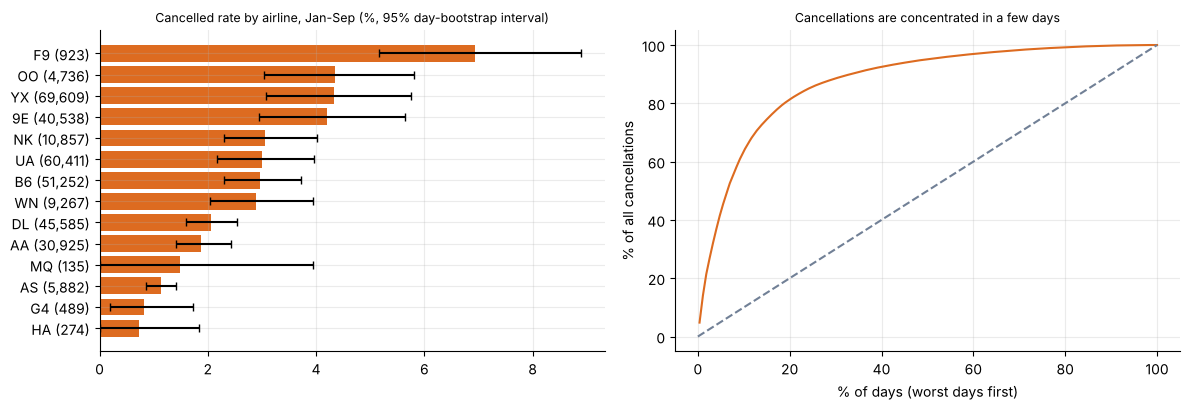

The worst 27 days (10% of 273 days) hold 63.2% of all cancellations.


carrier,F9,OO,YX,9E,NK,UA,B6,WN,DL,AA,MQ,AS,G4,HA
flights,923.00,4736.00,69609.00,40538.00,10857.00,60411.00,51252.00,9267.00,45585.00,30925.00,135.00,5882.00,489.00,274.00
rate,6.93,4.35,4.34,4.20,3.06,3.00,2.97,2.89,2.06,1.87,1.48,1.14,0.82,0.73
low,5.17,3.03,3.07,2.95,2.30,2.16,2.30,2.03,1.60,1.41,0.00,0.85,0.19,0.00
high,8.89,5.81,5.75,5.64,4.01,3.96,3.72,3.94,2.54,2.42,3.94,1.42,1.73,1.83


In [8]:
canc_car = day_bootstrap_rate(tr, "carrier", y="cancelled").sort_values("rate")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
lab = [f"{c} ({int(n):,})" for c, n in zip(canc_car.index, canc_car.flights)]
ax[0].barh(lab, 100 * canc_car.rate, color=ORANGE, xerr=[100 * (canc_car.rate - canc_car.low), 100 * (canc_car.high - canc_car.rate)], capsize=3)
ax[0].set_title("Cancelled rate by airline, Jan-Sep (%, 95% day-bootstrap interval)", fontsize=9)

daily = tr.groupby("date").agg(flights=("late", "size"), canc=("cancelled", "sum"), late=("late", "mean"))
cum = daily.sort_values("canc", ascending=False).canc.cumsum() / daily.canc.sum()
ax[1].plot(100 * np.arange(1, len(cum) + 1) / len(cum), 100 * cum.values, color=ORANGE)
ax[1].plot([0, 100], [0, 100], color=GREY, ls="--")
ax[1].set_xlabel("% of days (worst days first)"); ax[1].set_ylabel("% of all cancellations")
ax[1].set_title("Cancellations are concentrated in a few days", fontsize=9)
plt.tight_layout(); plt.show()
top10 = int(round(0.10 * len(cum)))
print(f"The worst {top10} days (10% of {len(cum)} days) hold {100 * cum.iloc[top10 - 1]:.1f}% of all cancellations.")
display(canc_car.assign(rate=100 * canc_car.rate, low=100 * canc_car.low, high=100 * canc_car.high).round(2).iloc[::-1].T)

## Are the 3 most important findings real, or chance?

The three candidates, chosen from the tables above because they are the biggest and the most useful for the business:

* **A. The hour of the day.** Early flights are rarely late, evening flights often are.
* **B. A few "bad days" carry most of the disruption.** A bad day is defined here as a day when at least 45% of flights were late or cancelled (about the worst 10% of days).
* **C. Airlines differ, even after taking out hour, airport and distance.**

For each: an interval from the day bootstrap, a chi-square test with its effect size, and where useful a random-chance comparison.

In [9]:
# A. hour of the day: early (hours 5-8) vs evening (hours 19-22)
tr["period"] = np.select([tr.hour.between(5, 8), tr.hour.between(19, 22)], ["early 5-8", "evening 19-22"], "other")
pa = tr[tr.period != "other"].groupby(["date", "period"]).late.agg(["sum", "count"]).unstack(fill_value=0)
pa.columns = [f"{a}_{b}" for a, b in pa.columns]
gapA = day_bootstrap(pa, lambda s: 100 * (s["sum_evening 19-22"] / s["count_evening 19-22"] - s["sum_early 5-8"] / s["count_early 5-8"]))
rates = tr[tr.period != "other"].groupby("period").late.mean() * 100
chiA = chi2_effect(pd.crosstab(tr.hour, tr.late))
print(f"A. late rate early 5-8: {rates['early 5-8']:.1f}% | evening 19-22: {rates['evening 19-22']:.1f}% | gap {gapA[0]:.1f} points, 95% interval {gapA[1]:.1f} to {gapA[2]:.1f}")
print(f"   chi-square hour vs late: chi2 = {chiA['chi2']:.0f}, dof = {chiA['dof']}, {fmt_p(chiA['p'])}, Cramer's V = {chiA['cramers_v']:.3f}")

# B. bad days
daily["bad"] = daily.late >= 0.45
tr["bad_day"] = tr.date.map(daily.bad)
share_flights = tr.bad_day.mean(); share_canc = tr.cancelled[tr.bad_day].sum() / tr.cancelled.sum(); share_late = tr.late[tr.bad_day].sum() / tr.late.sum()
print(f"B. bad days: {int(daily.bad.sum())} of {len(daily)} days ({100 * daily.bad.mean():.1f}%) | {100 * share_flights:.1f}% of flights | "
      f"{100 * share_late:.1f}% of all late-or-cancelled flights | {100 * share_canc:.1f}% of all cancellations")
rng = np.random.default_rng(SEED)
dcan = daily.canc.values; k = int(daily.bad.sum())
sim = np.array([dcan[rng.choice(len(dcan), k, replace=False)].sum() / dcan.sum() for _ in range(10_000)])
print(f"   if {k} days were picked at random they would hold {100 * sim.mean():.1f}% of cancellations on average (largest of 10,000 tries: {100 * sim.max():.1f}%).")
print(f"   observed share {100 * share_canc:.1f}% is above all 10,000 random picks: {bool((sim < share_canc).all())}")

# C. airlines
chiC = chi2_effect(pd.crosstab(tr.carrier, tr.late))
yx, b6 = carrier_oe.loc["YX"], carrier_oe.loc["B6"]
dd = tr[tr.carrier.isin(["YX", "B6"])].groupby(["date", "carrier"]).late.agg(["sum", "count"]).unstack(fill_value=0)
dd.columns = [f"{a}_{b}" for a, b in dd.columns]
gapC = day_bootstrap(dd, lambda s: 100 * (s["sum_B6"] / s["count_B6"] - s["sum_YX"] / s["count_YX"]))
print(f"C. late rate B6 {100 * tr.late[tr.carrier == 'B6'].mean():.1f}% vs YX {100 * tr.late[tr.carrier == 'YX'].mean():.1f}%: gap {gapC[0]:.1f} points, 95% interval {gapC[1]:.1f} to {gapC[2]:.1f}")
print(f"   after taking out hour, month, origin and distance: B6 observed/expected {b6['observed / expected']:.2f} ({b6['low']:.2f} to {b6['high']:.2f}); YX {yx['observed / expected']:.2f} ({yx['low']:.2f} to {yx['high']:.2f})")
print(f"   chi-square airline vs late: chi2 = {chiC['chi2']:.0f}, dof = {chiC['dof']}, {fmt_p(chiC['p'])}, Cramer's V = {chiC['cramers_v']:.3f}")

A. late rate early 5-8: 13.4% | evening 19-22: 39.9% | gap 26.5 points, 95% interval 24.2 to 28.9
   chi-square hour vs late: chi2 = 17194, dof = 18, p < 1e-300, Cramer's V = 0.228
B. bad days: 27 of 273 days (9.9%) | 9.8% of flights | 21.9% of all late-or-cancelled flights | 57.5% of all cancellations
   if 27 days were picked at random they would hold 10.0% of cancellations on average (largest of 10,000 tries: 27.1%).
   observed share 57.5% is above all 10,000 random picks: True


C. late rate B6 35.1% vs YX 17.6%: gap 17.4 points, 95% interval 15.9 to 18.9
   after taking out hour, month, origin and distance: B6 observed/expected 1.26 (1.20 to 1.31); YX 0.76 (0.68 to 0.83)
   chi-square airline vs late: chi2 = 7259, dof = 13, p < 1e-300, Cramer's V = 0.148


## Why does it happen? Looking for another explanation

### 1. Is the rise through the day just a chain of delays, or something about the hour itself?

If delays only snowball along the day, the first flight of a plane should be on time and the rise should come from later flights. Two checks: (a) the late rate by hour on **ordinary days only** (bad days removed), and (b) among **flights that left**, the late rate by hour for the **first** NYC departure of each plane that day versus later ones. (Cancelled flights have no plane in some airlines' data, so check (b) uses departed flights.)

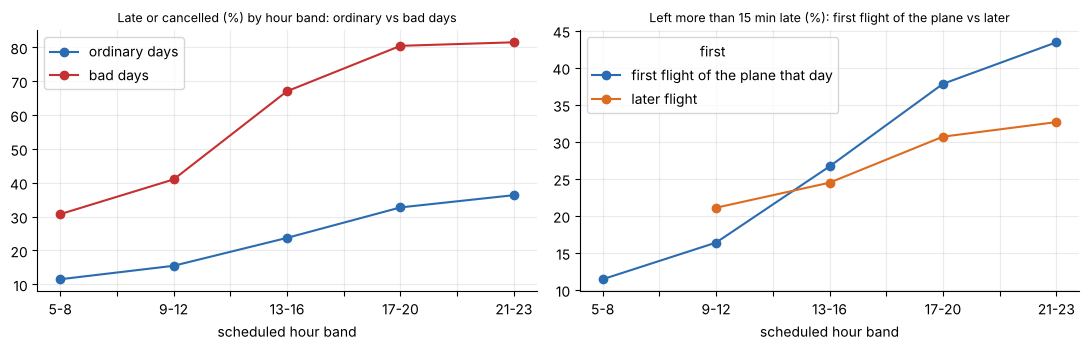

hb,5-8,9-12,13-16,17-20,21-23
ordinary days,11.5,15.5,23.7,32.7,36.3
bad days,30.7,41.0,67.0,80.4,81.5


hb,5-8,9-12,13-16,17-20,21-23
first,,,,,
first flight of the plane that day,11.4,16.4,26.7,37.8,43.4
later flight,<NA>,21.1,24.5,30.7,32.7


Flights behind each cell of the second table:


hb,5-8,9-12,13-16,17-20,21-23
first,,,,,
first flight of the plane that day,67105,71406,43447,37273,7211
later flight,29,5615,35700,39491,13092


In [10]:
hb = pd.cut(tr.hour, [4, 8, 12, 16, 20, 24], labels=["5-8", "9-12", "13-16", "17-20", "21-23"])
tab_a = tr.assign(hb=hb).groupby(["hb", "bad_day"], observed=True).late.mean().unstack() * 100
tab_a.columns = ["ordinary days", "bad days"]

t = tr[tr.tailnum.notna() & tr.departed].sort_values(["tailnum", "sched_dt"]).copy()
t["order"] = t.groupby(["tailnum", "date"]).cumcount() + 1
t["first"] = np.where(t.order == 1, "first flight of the plane that day", "later flight")
t["hb"] = pd.cut(t.hour, [4, 8, 12, 16, 20, 24], labels=["5-8", "9-12", "13-16", "17-20", "21-23"])
g_b = t.groupby(["hb", "first"], observed=True).late15.agg(["mean", "size"]).unstack()
tab_b = 100 * g_b["mean"].where(g_b["size"] >= 500)          # groups under 500 flights are not shown (too small)
n_b = g_b["size"]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
tab_a.plot(ax=ax[0], marker="o", color=[BLUE, RED]); ax[0].set_title("Late or cancelled (%) by hour band: ordinary vs bad days", fontsize=9); ax[0].set_xlabel("scheduled hour band")
tab_b.plot(ax=ax[1], marker="o", color=[BLUE, ORANGE]); ax[1].set_title("Left more than 15 min late (%): first flight of the plane vs later", fontsize=9); ax[1].set_xlabel("scheduled hour band")
plt.tight_layout(); plt.show()
display(tab_a.round(1).T); display(tab_b.round(1).T)
print("Flights behind each cell of the second table:"); display(n_b.T)

### 2. The weekday pattern in cancellations: real, or an accident of which days the bad days fell on?

Cancellation rates differ a lot by weekday in the raw data. But bad days hold most of the cancellations (above). If the bad days happened to land on certain weekdays, the weekday pattern would be an accident. Check: remove the bad days and recompute, count bad days per weekday, and ask how often random placement of that many bad days would leave one weekday with none.

In [11]:
dw = tr.groupby("dow").agg(all_days=("cancelled", "mean"))
dw["without bad days"] = tr[~tr.bad_day].groupby("dow").cancelled.mean()
dw["bad days in this weekday"] = daily[daily.bad].groupby(daily[daily.bad].index.dayofweek).size()
dw["bad days in this weekday"] = dw["bad days in this weekday"].fillna(0).astype(int)
dw.index = dow_names
display((dw.assign(**{"all_days": 100 * dw.all_days, "without bad days": 100 * dw["without bad days"]})).round(2).T)

cv_all = chi2_effect(pd.crosstab(tr.dow, tr.cancelled))["cramers_v"]
cv_ok = chi2_effect(pd.crosstab(tr[~tr.bad_day].dow, tr[~tr.bad_day].cancelled))["cramers_v"]
print(f"Cramer's V weekday vs cancelled: all days {cv_all:.3f} | without bad days {cv_ok:.3f}")

# how likely is it that some weekday gets no bad day if bad days fall on random days?
weekday_of_day = daily.index.dayofweek.values
rng = np.random.default_rng(SEED)
empty = 0
for _ in range(20_000):
    pick = rng.choice(len(daily), int(daily.bad.sum()), replace=False)
    empty += len(np.unique(weekday_of_day[pick])) < 7
print(f"If {int(daily.bad.sum())} bad days fell on random days, some weekday would get none in {100 * empty / 20_000:.1f}% of 20,000 simulations.")

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
all_days,3.49,3.58,2.07,1.51,3.58,3.46,4.73
without bad days,1.89,1.20,1.32,1.51,1.74,1.76,1.07
bad days in this weekday,4.00,4.00,4.00,0.00,5.00,4.00,6.00


Cramer's V weekday vs cancelled: all days 0.057 | without bad days 0.023


If 27 bad days fell on random days, some weekday would get none in 8.7% of 20,000 simulations.


### 3. Does the weather at the airport explain the bad days?

If the bad days were caused by weather at JFK, LGA and EWR, those days should show much more rain, low visibility or wind in the data.

In [12]:
w = tr[tr.precip.notna()].copy()
w["rain"] = w.precip > 0
by_day_w = w.groupby("date").agg(rain_share=("rain", "mean"), low_visib_share=("low_visib", "mean"), gust25_share=("gust25", "mean"))
by_day_w["bad"] = daily.bad
cmp_w = by_day_w.groupby("bad").mean().mul(100).round(1)
cmp_w.index = ["ordinary days", "bad days"]; cmp_w.columns = ["% of flights with rain/snow", "% with visibility < 3 mi", "% with gust >= 25 mph"]
display(cmp_w)
bad_days = by_day_w[by_day_w.bad]
print(f"Bad days with rain or snow for under 10% of their flights: {int((bad_days.rain_share < 0.10).sum())} of {len(bad_days)}")
print(f"Bad days with no flight in visibility under 3 miles: {int((bad_days.low_visib_share == 0).sum())} of {len(bad_days)}")
print("Bad days by month:", daily[daily.bad].groupby(daily[daily.bad].index.month).size().to_dict())

# Is "a rainy day" enough to predict a bad day?  A rainy day = at least 20% of its flights in rain or snow.
by_day_w["rainy_day"] = by_day_w.rain_share >= 0.20
x = pd.crosstab(by_day_w.rainy_day, by_day_w.bad)
rainy_bad = x.loc[True, True] / x.loc[True].sum(); bad_rainy = x.loc[True, True] / x.loc[:, True].sum()
print(f"Rainy days (rain/snow for 20%+ of flights): {int(x.loc[True].sum())} of {len(by_day_w)} days. Of them, {100 * rainy_bad:.0f}% are bad days.")
print(f"Of the {int(x.loc[:, True].sum())} bad days, {100 * bad_rainy:.0f}% were rainy days.")

,% of flights with rain/snow,% with visibility < 3 mi,% with gust >= 25 mph
ordinary days,11.6,2.116304,3.418202
bad days,27.6,6.465837,6.14265


Bad days with rain or snow for under 10% of their flights: 6 of 27
Bad days with no flight in visibility under 3 miles: 12 of 27
Bad days by month: {1: 1, 3: 2, 4: 4, 6: 6, 7: 9, 9: 5}


Rainy days (rain/snow for 20%+ of flights): 66 of 273 days. Of them, 21% are bad days.
Of the 27 bad days, 52% were rainy days.


### 4. A data-quality finding that matters for the models: which cancelled flights have no plane?

Task 1 showed that every flight without a tail number is cancelled. Is that true for all airlines?

In [13]:
cm = tr[tr.cancelled == 1].groupby("carrier").agg(cancelled=("tail_missing", "size"), without_tail=("tail_missing", "sum"))
cm["share without tail %"] = (100 * cm.without_tail / cm.cancelled).round(0)
display(cm.sort_values("cancelled", ascending=False).T)
print("Flights that are NOT cancelled and have no tail:", int(((tr.cancelled == 0) & tr.tail_missing).sum()))

carrier,YX,UA,9E,B6,DL,AA,NK,WN,OO,AS,F9,G4,MQ,HA
cancelled,3019.0,1812.0,1702.0,1520.0,938.0,578.0,332.0,268.0,206.0,67.0,64.0,4.0,2.0,2.0
without_tail,8.0,1812.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,64.0,3.0,0.0,2.0
share without tail %,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,75.0,0.0,100.0


Flights that are NOT cancelled and have no tail: 0


So the missing tail number is an **airline-specific reporting habit**: for some airlines (United, Frontier, Hawaiian, most of Allegiant) the tail is missing for cancelled flights, while other carriers usually retain it. Consequence for modeling: a missing-plane flag would reveal cancellation. D10 avoids that leak by filling each plane feature from the carrier's Jan-Sep training median or mode, with a global training fallback if a carrier has no usable aircraft.

### 5. Do airlines cancel differently on ordinary days, or only when a bad day hits?

In [14]:
big_car = tr.carrier.value_counts()[lambda s: s >= 9000].index
cc2 = tr[tr.carrier.isin(big_car)].groupby(["carrier", "bad_day"]).cancelled.mean().unstack() * 100
cc2.columns = ["ordinary days %", "bad days %"]
display(cc2.sort_values("bad days %", ascending=False).round(2).T)

carrier,YX,9E,UA,WN,NK,B6,AA,DL
ordinary days %,1.66,1.69,1.37,1.4,1.65,1.66,1.01,1.33
bad days %,29.43,27.01,17.86,16.7,15.79,15.54,9.91,8.60


## One chart per finding

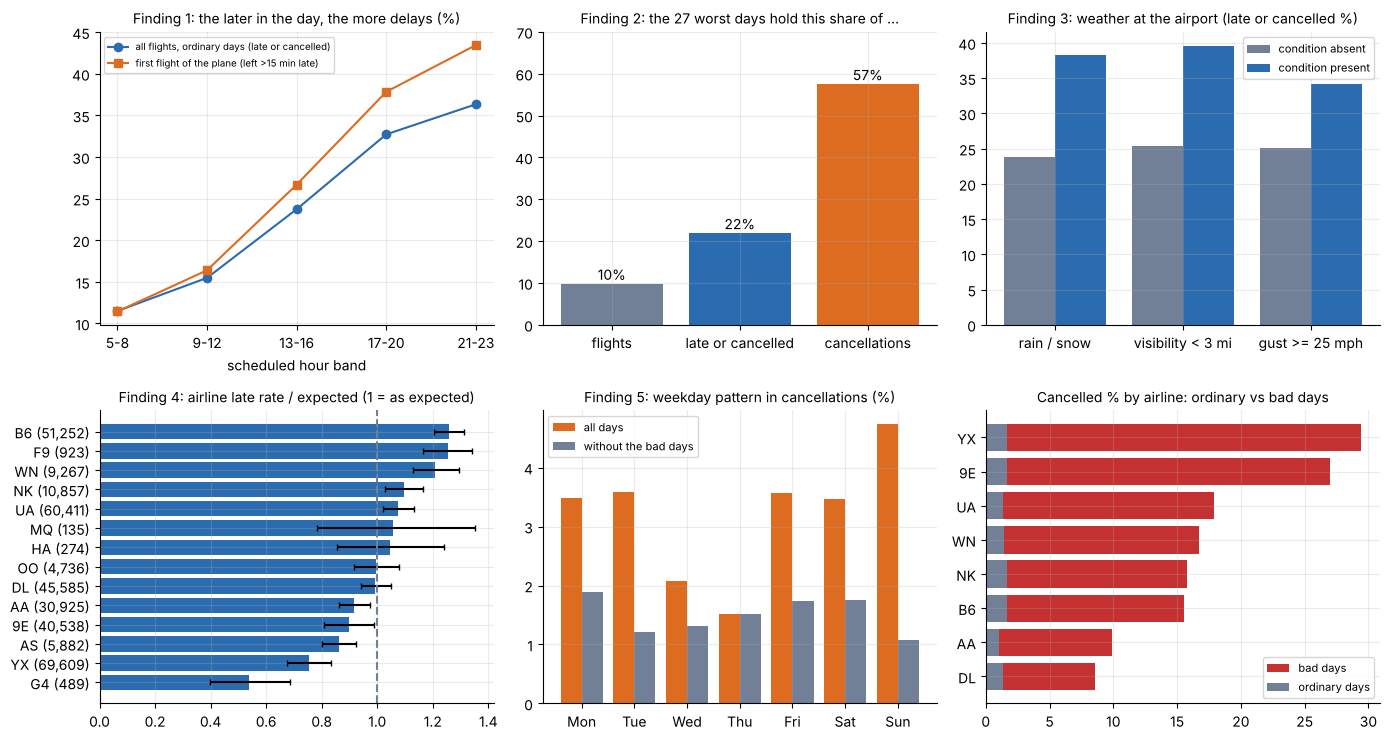

In [15]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7.5))
bands = list(tab_a.index)
# F1 hour
ax[0, 0].plot(bands, tab_a["ordinary days"], marker="o", color=BLUE, label="all flights, ordinary days (late or cancelled)")
ax[0, 0].plot(bands, tab_b["first flight of the plane that day"], marker="s", color=ORANGE, label="first flight of the plane (left >15 min late)")
ax[0, 0].set_title("Finding 1: the later in the day, the more delays (%)", fontsize=10); ax[0, 0].set_xlabel("scheduled hour band"); ax[0, 0].legend(fontsize=7)
# F2 bad days
vals = [100 * share_flights, 100 * share_late, 100 * share_canc]
ax[0, 1].bar(["flights", "late or cancelled", "cancellations"], vals, color=[GREY, BLUE, ORANGE])
for k, v in enumerate(vals): ax[0, 1].text(k, v + 1, f"{v:.0f}%", ha="center")
ax[0, 1].set_title(f"Finding 2: the {int(daily.bad.sum())} worst days hold this share of ...", fontsize=10); ax[0, 1].set_ylim(0, 70)
# F3 weather
conds = [("rain or snow in the hour (UTC-aware join)", "rain / snow"), ("visibility under 3 miles (UTC-aware join)", "visibility < 3 mi"), ("wind gust 25 mph or more (UTC-aware join)", "gust >= 25 mph")]
x = np.arange(3)
ax[0, 2].bar(x - 0.2, [wx.loc[c, "late % if no"] for c, _ in conds], 0.4, color=GREY, label="condition absent")
ax[0, 2].bar(x + 0.2, [wx.loc[c, "late % if yes"] for c, _ in conds], 0.4, color=BLUE, label="condition present")
ax[0, 2].set_xticks(x); ax[0, 2].set_xticklabels([l for _, l in conds]); ax[0, 2].legend(fontsize=8)
ax[0, 2].set_title("Finding 3: weather at the airport (late or cancelled %)", fontsize=10)
# F4 airlines
co = carrier_oe.sort_values("observed / expected")
ax[1, 0].barh([f"{c} ({int(n):,})" for c, n in zip(co.index, co.flights)], co["observed / expected"], color=BLUE,
              xerr=[co["observed / expected"] - co.low, co.high - co["observed / expected"]], capsize=2)
ax[1, 0].axvline(1, color=GREY, ls="--"); ax[1, 0].set_title("Finding 4: airline late rate / expected (1 = as expected)", fontsize=10)
# F5 weekday
ax[1, 1].bar(np.arange(7) - 0.2, 100 * dw.all_days, 0.4, color=ORANGE, label="all days")
ax[1, 1].bar(np.arange(7) + 0.2, 100 * dw["without bad days"], 0.4, color=GREY, label="without the bad days")
ax[1, 1].set_xticks(range(7)); ax[1, 1].set_xticklabels(dow_names); ax[1, 1].legend(fontsize=8)
ax[1, 1].set_title("Finding 5: weekday pattern in cancellations (%)", fontsize=10)
# extra: cancellation rate by airline on ordinary vs bad days
cc2s = cc2.sort_values("bad days %")
ax[1, 2].barh(cc2s.index, cc2s["bad days %"], color=RED, label="bad days"); ax[1, 2].barh(cc2s.index, cc2s["ordinary days %"], color=GREY, label="ordinary days")
ax[1, 2].legend(fontsize=8); ax[1, 2].set_title("Cancelled % by airline: ordinary vs bad days", fontsize=10)
plt.tight_layout(); plt.show()

## The 5 best findings (numbers are read from the cells above, not typed by hand)

In [16]:
rr = wx.loc["rain or snow in the hour (UTC-aware join)"]; rl = wx.loc["rain or snow in the hour (literal join)"]
vv = wx.loc["visibility under 3 miles (UTC-aware join)"]; gg = wx.loc["wind gust 25 mph or more (UTC-aware join)"]
oe = carrier_oe["observed / expected"]
thu = dw.loc["Thu"]
md = f"""
### Finding 1. Delays build up through the day, and not only because planes pass delays on
* **Number.** Flights scheduled 5-8 are late or cancelled {rates['early 5-8']:.1f}% of the time, flights scheduled 19-22 are {rates['evening 19-22']:.1f}%: a gap of **{gapA[0]:.1f} points** (95% day-bootstrap interval {gapA[1]:.1f} to {gapA[2]:.1f}).
* **Check that it is real.** The gap is far outside its interval. Chi-square hour vs late: {fmt_p(chiA['p'])}, Cramer's V = {chiA['cramers_v']:.2f} (a moderate effect).
* **Another explanation?** On ordinary days (bad days removed) the rate still rises from {tab_a.loc['5-8','ordinary days']:.1f}% to {tab_a.loc['21-23','ordinary days']:.1f}%. Among a plane's **first** NYC departure of the day (so no earlier NYC delay of that plane), the share leaving over 15 minutes late rises from {tab_b.loc['5-8','first flight of the plane that day']:.1f}% to {tab_b.loc['21-23','first flight of the plane that day']:.1f}%. So the rise is not only a chain of delays on the same plane (the plane may still have been delayed before reaching New York; the data cannot show that).
* **Action.** Warn clients on evening flights first, and let the model use how late the airport already is at the moment of prediction (Task 5).

### Finding 2. A few bad days carry most of the disruption
* **Number.** {int(daily.bad.sum())} of {len(daily)} days ({100*daily.bad.mean():.0f}%) had 45% or more of their flights late or cancelled. They hold **{100*share_canc:.1f}% of all cancellations** and {100*share_late:.1f}% of all late-or-cancelled flights, with only {100*share_flights:.1f}% of the flights.
* **Check that it is real.** {int(daily.bad.sum())} days picked at random would hold {100*sim.mean():.1f}% of the cancellations on average; the largest of 10,000 random picks was {100*sim.max():.1f}%. The real share is above all 10,000.
* **Another explanation?** Weather at the airports is part of it: {cmp_w.loc['bad days'].iloc[0]:.1f}% of flights on bad days meet rain or snow, against {cmp_w.loc['ordinary days'].iloc[0]:.1f}% on ordinary days. But it is not enough: only {100*rainy_bad:.0f}% of rainy days are bad days, and {100*(1-bad_rainy):.0f}% of the bad days were not rainy days. The data has no weather on the route or at the destination, no air-traffic information and no cancellation reasons.
* **Action.** The agency cannot predict these days from the timetable alone: it needs a real-time trigger (a bad-day alert) on top of the model. Cancellation predictions are therefore likely to have low precision (to be measured in Task 6), and the decision card must say so.

### Finding 3. Weather at the airport matters, with a moderate effect
* **Number.** In hours with rain or snow {rr['late % if yes']:.1f}% of flights are late or cancelled, against {rr['late % if no']:.1f}% otherwise: **+{rr['gap (points)']:.1f} points** (interval {rr['gap low']:.1f} to {rr['gap high']:.1f}). Low visibility (under 3 miles) is {vv['obs/exp if yes (same hour, month, origin)']:.2f} times the rate expected for the same hour, month and airport; strong gusts (25 mph or more) {gg['obs/exp if yes (same hour, month, origin)']:.2f} times.
* **Check that it is real.** After taking out hour, month and origin, rain is still {rr['obs/exp if yes (same hour, month, origin)']:.2f} times the expected rate (interval {rr['obs/exp low']:.2f} to {rr['obs/exp high']:.2f}). So hour and season do not explain it away.
* **Join check.** With the literal join of the course sheet the rain gap is {rl['gap (points)']:.1f} points against {rr['gap (points)']:.1f} with the UTC-aware join. The two intervals overlap, so on this measure the choice of join changes the size of the effect only slightly; the UTC-aware join is still the correct one.
* **Action.** Use weather in the models, in two versions (the weather of the scheduled hour, and only what is known two hours before). Rain affects {rr['share of flights %']:.0f}% of flights, so weather alone cannot carry the prediction.

### Finding 4. Airlines differ, even after taking out hour, airport and distance, and they cancel very differently on bad days
* **Number.** JetBlue (B6) is late or cancelled **{oe['B6']:.2f} times** the rate expected for its flights (interval {carrier_oe.loc['B6','low']:.2f} to {carrier_oe.loc['B6','high']:.2f}); Frontier (F9) {oe['F9']:.2f}, Southwest (WN) {oe['WN']:.2f}; Republic (YX) {oe['YX']:.2f} and Allegiant (G4) {oe['G4']:.2f}. The raw gap between B6 and YX is {gapC[0]:.1f} points (interval {gapC[1]:.1f} to {gapC[2]:.1f}).
* **Check that it is real.** Chi-square airline vs late: {fmt_p(chiC['p'])}, Cramer's V = {chiC['cramers_v']:.2f}. The intervals of B6 and YX do not overlap and are on opposite sides of 1. Small airlines (F9 with {int(carrier_oe.loc['F9','flights']):,} flights, G4 {int(carrier_oe.loc['G4','flights']):,}, HA, MQ) have wide intervals: read them with care.
* **Cancellations.** On ordinary days the large airlines cancel {cc2['ordinary days %'].min():.1f}% to {cc2['ordinary days %'].max():.1f}% of their flights. On bad days it is {cc2.loc['YX','bad days %']:.0f}% for Republic (YX) and {cc2.loc['9E','bad days %']:.0f}% for Endeavor (9E), against {cc2.loc['DL','bad days %']:.0f}% for Delta and {cc2.loc['AA','bad days %']:.0f}% for American. The airlines differ in how well they hold up on bad days, not on ordinary days.
* **Action.** Give the airline a role in the risk score; warn clients of the high-ratio airlines earlier; on a bad day, rebook first the clients flying the airlines that cancel most (YX, 9E).

### Finding 5 (a strange pattern, explained). The weekday pattern in cancellations is mostly an accident
* **What looks strange.** Cancelled rates by weekday range from {100*dw.all_days.min():.1f}% to {100*dw.all_days.max():.1f}%: Thursday is the best day ({thu['all_days']*100:.2f}%), Sunday the worst ({100*dw.loc['Sun','all_days']:.2f}%).
* **Why.** The bad days of Finding 2 hold most cancellations, and they did not fall evenly on weekdays: Thursday had {int(thu['bad days in this weekday'])} bad days, Sunday {int(dw.loc['Sun','bad days in this weekday'])}. Without the bad days the weekdays range only from {100*dw['without bad days'].min():.1f}% to {100*dw['without bad days'].max():.1f}% and Cramer's V drops from {cv_all:.3f} to {cv_ok:.3f} (almost no effect).
* **Check that it is chance.** If {int(daily.bad.sum())} bad days fell on random days, some weekday would get none in {100*empty/20_000:.1f}% of 20,000 simulations, so an empty Thursday is not unusual.
* **Action.** Do not tell the business that "Thursday is safer" and do not use the weekday as a cancellation driver; the weekday stays in the models only as a minor calendar column and its importance must be checked in Task 6.
"""
display(Markdown(md))


### Finding 1. Delays build up through the day, and not only because planes pass delays on
* **Number.** Flights scheduled 5-8 are late or cancelled 13.4% of the time, flights scheduled 19-22 are 39.9%: a gap of **26.5 points** (95% day-bootstrap interval 24.2 to 28.9).
* **Check that it is real.** The gap is far outside its interval. Chi-square hour vs late: p < 1e-300, Cramer's V = 0.23 (a moderate effect).
* **Another explanation?** On ordinary days (bad days removed) the rate still rises from 11.5% to 36.3%. Among a plane's **first** NYC departure of the day (so no earlier NYC delay of that plane), the share leaving over 15 minutes late rises from 11.4% to 43.4%. So the rise is not only a chain of delays on the same plane (the plane may still have been delayed before reaching New York; the data cannot show that).
* **Action.** Warn clients on evening flights first, and let the model use how late the airport already is at the moment of prediction (Task 5).

### Finding 2. A few bad days carry most of the disruption
* **Number.** 27 of 273 days (10%) had 45% or more of their flights late or cancelled. They hold **57.5% of all cancellations** and 21.9% of all late-or-cancelled flights, with only 9.8% of the flights.
* **Check that it is real.** 27 days picked at random would hold 10.0% of the cancellations on average; the largest of 10,000 random picks was 27.1%. The real share is above all 10,000.
* **Another explanation?** Weather at the airports is part of it: 27.6% of flights on bad days meet rain or snow, against 11.6% on ordinary days. But it is not enough: only 21% of rainy days are bad days, and 48% of the bad days were not rainy days. The data has no weather on the route or at the destination, no air-traffic information and no cancellation reasons.
* **Action.** The agency cannot predict these days from the timetable alone: it needs a real-time trigger (a bad-day alert) on top of the model. Cancellation predictions are therefore likely to have low precision (to be measured in Task 6), and the decision card must say so.

### Finding 3. Weather at the airport matters, with a moderate effect
* **Number.** In hours with rain or snow 38.3% of flights are late or cancelled, against 23.8% otherwise: **+14.5 points** (interval 11.1 to 18.1). Low visibility (under 3 miles) is 1.54 times the rate expected for the same hour, month and airport; strong gusts (25 mph or more) 1.38 times.
* **Check that it is real.** After taking out hour, month and origin, rain is still 1.48 times the expected rate (interval 1.37 to 1.59). So hour and season do not explain it away.
* **Join check.** With the literal join of the course sheet the rain gap is 12.6 points against 14.5 with the UTC-aware join. The two intervals overlap, so on this measure the choice of join changes the size of the effect only slightly; the UTC-aware join is still the correct one.
* **Action.** Use weather in the models, in two versions (the weather of the scheduled hour, and only what is known two hours before). Rain affects 13% of flights, so weather alone cannot carry the prediction.

### Finding 4. Airlines differ, even after taking out hour, airport and distance, and they cancel very differently on bad days
* **Number.** JetBlue (B6) is late or cancelled **1.26 times** the rate expected for its flights (interval 1.20 to 1.31); Frontier (F9) 1.25, Southwest (WN) 1.21; Republic (YX) 0.76 and Allegiant (G4) 0.54. The raw gap between B6 and YX is 17.4 points (interval 15.9 to 18.9).
* **Check that it is real.** Chi-square airline vs late: p < 1e-300, Cramer's V = 0.15. The intervals of B6 and YX do not overlap and are on opposite sides of 1. Small airlines (F9 with 923 flights, G4 489, HA, MQ) have wide intervals: read them with care.
* **Cancellations.** On ordinary days the large airlines cancel 1.0% to 1.7% of their flights. On bad days it is 29% for Republic (YX) and 27% for Endeavor (9E), against 9% for Delta and 10% for American. The airlines differ in how well they hold up on bad days, not on ordinary days.
* **Action.** Give the airline a role in the risk score; warn clients of the high-ratio airlines earlier; on a bad day, rebook first the clients flying the airlines that cancel most (YX, 9E).

### Finding 5 (a strange pattern, explained). The weekday pattern in cancellations is mostly an accident
* **What looks strange.** Cancelled rates by weekday range from 1.5% to 4.7%: Thursday is the best day (1.51%), Sunday the worst (4.73%).
* **Why.** The bad days of Finding 2 hold most cancellations, and they did not fall evenly on weekdays: Thursday had 0 bad days, Sunday 6. Without the bad days the weekdays range only from 1.1% to 1.9% and Cramer's V drops from 0.057 to 0.023 (almost no effect).
* **Check that it is chance.** If 27 bad days fell on random days, some weekday would get none in 8.7% of 20,000 simulations, so an empty Thursday is not unusual.
* **Action.** Do not tell the business that "Thursday is safer" and do not use the weekday as a cancellation driver; the weekday stays in the models only as a minor calendar column and its importance must be checked in Task 6.


### Data-quality finding for the models (from section 4 above)

The tail number is missing for **all** cancelled United (UA) flights and all cancelled Frontier (F9) flights and for most Allegiant and Hawaiian ones, but not for cancelled flights of the other airlines. This airline-specific reporting habit means missingness itself must not be a model feature. D10 fills plane columns using Jan-Sep carrier medians or modes, with a global training fallback where needed.

## The second prediction (decision D3)

**What we predict:** for every flight, **will it be cancelled** (no departure time)? **For whom and when:** for each flight of the agency's clients' itineraries, two hours before scheduled departure. **How the business uses it:** the agency contacts the clients of the flights with the highest risk and offers a rebooking before the cancellation happens (PROJECTS sheet: "rebook clients before the cancellation").

**Which of the three questions it answers:** Q3. It is different from the first prediction (late or cancelled): it asks only about the rare, costly event, and the action is a rebooking, not a warning.

In [17]:
val_prev = tr[tr.month.isin(VAL_MONTHS)].cancelled.mean()
print(f"Training part: {int(tr.cancelled.sum()):,} cancelled flights out of {len(tr):,} ({100 * tr.cancelled.mean():.2f}%).")
print(f"Validation months (Jul-Sep): cancelled rate {100 * val_prev:.2f}%.  Fallback gate (plan, Task 2 step 6): at least one model must reach PR-AUC above 1.5 x {val_prev:.4f} = {1.5 * val_prev:.4f} on validation.")
print(f"Share of training cancellations on the {int(daily.bad.sum())} bad days: {100 * share_canc:.1f}%  (the model cannot see a bad day coming from the timetable).")

Training part: 10,514 cancelled flights out of 330,883 (3.18%).
Validation months (Jul-Sep): cancelled rate 5.12%.  Fallback gate (plan, Task 2 step 6): at least one model must reach PR-AUC above 1.5 x 0.0512 = 0.0768 on validation.
Share of training cancellations on the 27 bad days: 57.5%  (the model cannot see a bad day coming from the timetable).


**Known risk, stated now and not hidden.** In the test months (October to December) only 0.21% of flights are cancelled (224 flights, see Task 1) against 3.18% in training. Scores will be noisy, so Task 6 reports confidence intervals and compares with the dumb answer on the same part. If no model reaches the gate above on validation, the plan switches to the regression fallback (departure delay in minutes); that decision is taken on validation only.

## Summary of this notebook

* The three questions are answered with tables and charts (hour, weekday, month, origin, distance, destination, airline, weather, cancellations).
* Five findings, each with a number, a chart, a check that it is not chance (day-bootstrap intervals, chi-square with effect size, random-pick comparison) and an action. Finding 5 explains a pattern that looks strange.
* A new data-quality finding changes the plan for plane features in Task 5.
* The second prediction (cancelled) is written down with its question, its use and its known risk.